implementing actual zerr into tables

In [1]:
from astropy.table import Table
from astropy.constants import c
from astropy import units as u

import numpy as np

from tqdm import tqdm

from scipy.optimize import minimize

import sys
sys.path.append('..')

from get_cutouts import get_cutout

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse


In [2]:
SGA = Table.read('/global/cfs/cdirs/cosmo/data/sga/2020/SGA-2020.fits', 'ELLIPSE')

SGA_dict = {}
for i in range(len(SGA)):
    SGA_dict[SGA['SGA_ID'][i]] = i

SGA[:5]

SGA_ID,SGA_GALAXY,GALAXY,PGC,RA_LEDA,DEC_LEDA,MORPHTYPE,PA_LEDA,D25_LEDA,BA_LEDA,Z_LEDA,SB_D25_LEDA,MAG_LEDA,BYHAND,REF,GROUP_ID,GROUP_NAME,GROUP_MULT,GROUP_PRIMARY,GROUP_RA,GROUP_DEC,GROUP_DIAMETER,BRICKNAME,RA,DEC,D26,D26_REF,PA,BA,RA_MOMENT,DEC_MOMENT,SMA_MOMENT,G_SMA50,R_SMA50,Z_SMA50,SMA_SB22,SMA_SB22.5,SMA_SB23,SMA_SB23.5,SMA_SB24,SMA_SB24.5,SMA_SB25,SMA_SB25.5,SMA_SB26,G_MAG_SB22,R_MAG_SB22,Z_MAG_SB22,G_MAG_SB22.5,R_MAG_SB22.5,Z_MAG_SB22.5,G_MAG_SB23,R_MAG_SB23,Z_MAG_SB23,G_MAG_SB23.5,R_MAG_SB23.5,Z_MAG_SB23.5,G_MAG_SB24,R_MAG_SB24,Z_MAG_SB24,G_MAG_SB24.5,R_MAG_SB24.5,Z_MAG_SB24.5,G_MAG_SB25,R_MAG_SB25,Z_MAG_SB25,G_MAG_SB25.5,R_MAG_SB25.5,Z_MAG_SB25.5,G_MAG_SB26,R_MAG_SB26,Z_MAG_SB26,SMA_SB22_ERR,SMA_SB22.5_ERR,SMA_SB23_ERR,SMA_SB23.5_ERR,SMA_SB24_ERR,SMA_SB24.5_ERR,SMA_SB25_ERR,SMA_SB25.5_ERR,SMA_SB26_ERR,G_MAG_SB22_ERR,R_MAG_SB22_ERR,Z_MAG_SB22_ERR,G_MAG_SB22.5_ERR,R_MAG_SB22.5_ERR,Z_MAG_SB22.5_ERR,G_MAG_SB23_ERR,R_MAG_SB23_ERR,Z_MAG_SB23_ERR,G_MAG_SB23.5_ERR,R_MAG_SB23.5_ERR,Z_MAG_SB23.5_ERR,G_MAG_SB24_ERR,R_MAG_SB24_ERR,Z_MAG_SB24_ERR,G_MAG_SB24.5_ERR,R_MAG_SB24.5_ERR,Z_MAG_SB24.5_ERR,G_MAG_SB25_ERR,R_MAG_SB25_ERR,Z_MAG_SB25_ERR,G_MAG_SB25.5_ERR,R_MAG_SB25.5_ERR,Z_MAG_SB25.5_ERR,G_MAG_SB26_ERR,R_MAG_SB26_ERR,Z_MAG_SB26_ERR,G_COG_PARAMS_MTOT,G_COG_PARAMS_M0,G_COG_PARAMS_ALPHA1,G_COG_PARAMS_ALPHA2,G_COG_PARAMS_CHI2,R_COG_PARAMS_MTOT,R_COG_PARAMS_M0,R_COG_PARAMS_ALPHA1,R_COG_PARAMS_ALPHA2,R_COG_PARAMS_CHI2,Z_COG_PARAMS_MTOT,Z_COG_PARAMS_M0,Z_COG_PARAMS_ALPHA1,Z_COG_PARAMS_ALPHA2,Z_COG_PARAMS_CHI2,ELLIPSEBIT
int64,bytes16,bytes29,int64,float64,float64,bytes21,float32,float32,float32,float32,float32,float32,bool,bytes13,int64,bytes35,int16,bool,float64,float64,float32,bytes8,float64,float64,float32,bytes4,float32,float32,float64,float64,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,int32
2,SGA-2020 2,PGC1283207,1283207,228.3770865,5.4232017,S?,152.2,0.36307806,0.724436,0.03463229,23.40448,16.976,False,LEDA-20181114,0,PGC1283207,1,True,228.3770865,5.4232017,0.36307806,2283p055,228.3770803831908,5.423191398593787,0.49470574,SB26,158.20142,0.545691,228.37700918822188,5.4232652570544015,10.897086,3.3509698,3.1147978,3.240862,5.902337,6.9126143,7.941369,8.997992,10.073601,11.199986,12.391357,13.561038,14.841172,16.966799,16.108246,15.486356,16.879545,16.024958,15.400715,16.818878,15.967034,15.341793,16.776297,15.925804,15.300776,16.746685,15.897334,15.272053,16.725166,15.876816,15.2521105,16.708357,15.862035,15.237181,16.696539,15.851936,15.226998,16.689613,15.844313,15.21976,0.013392451,0.02354,0.021872982,0.01736985,0.024445537,0.039866067,0.05026544,0.08455789,0.122911856,0.005682776,0.0054258136,0.0049038026,0.005588406,0.005323561,0.0047632363,0.00543534,0.005177031,0.0046343105,0.0053025587,0.005040888,0.0045181247,0.005206092,0.0049438984,0.0044374703,0.0051483097,0.0048758644,0.0043834248,0.0051032505,0.0048264163,0.004344248,0.0050705094,0.004792021,0.004319857,0.005054293,0.004765629,0.0043044444,16.65942,0.34037337,0.2978292,3.0239506,0.07928849,15.820566,0.2640441,0.34559453,3.3033552,0.003811298,15.195567,0.29826432,0.3001073,3.2333765,0.011723555,0
3,SGA-2020 3,PGC1310416,1310416,202.54443750000002,6.9345944,Sc,159.26,0.4017908,0.7816278,0.073888786,23.498482,16.85,False,LEDA-20181114,1,PGC1310416,1,True,202.54443750000002,6.9345944,0.4017908,

In [3]:
zerr_table = Table.read('/pscratch/sd/n/nravi/BTFR/loa_target_zerr.fits')

In [4]:
SGA[SGA['SGA_ID']==972325]

SGA_ID,SGA_GALAXY,GALAXY,PGC,RA_LEDA,DEC_LEDA,MORPHTYPE,PA_LEDA,D25_LEDA,BA_LEDA,Z_LEDA,SB_D25_LEDA,MAG_LEDA,BYHAND,REF,GROUP_ID,GROUP_NAME,GROUP_MULT,GROUP_PRIMARY,GROUP_RA,GROUP_DEC,GROUP_DIAMETER,BRICKNAME,RA,DEC,D26,D26_REF,PA,BA,RA_MOMENT,DEC_MOMENT,SMA_MOMENT,G_SMA50,R_SMA50,Z_SMA50,SMA_SB22,SMA_SB22.5,SMA_SB23,SMA_SB23.5,SMA_SB24,SMA_SB24.5,SMA_SB25,SMA_SB25.5,SMA_SB26,G_MAG_SB22,R_MAG_SB22,Z_MAG_SB22,G_MAG_SB22.5,R_MAG_SB22.5,Z_MAG_SB22.5,G_MAG_SB23,R_MAG_SB23,Z_MAG_SB23,G_MAG_SB23.5,R_MAG_SB23.5,Z_MAG_SB23.5,G_MAG_SB24,R_MAG_SB24,Z_MAG_SB24,G_MAG_SB24.5,R_MAG_SB24.5,Z_MAG_SB24.5,G_MAG_SB25,R_MAG_SB25,Z_MAG_SB25,G_MAG_SB25.5,R_MAG_SB25.5,Z_MAG_SB25.5,G_MAG_SB26,R_MAG_SB26,Z_MAG_SB26,SMA_SB22_ERR,SMA_SB22.5_ERR,SMA_SB23_ERR,SMA_SB23.5_ERR,SMA_SB24_ERR,SMA_SB24.5_ERR,SMA_SB25_ERR,SMA_SB25.5_ERR,SMA_SB26_ERR,G_MAG_SB22_ERR,R_MAG_SB22_ERR,Z_MAG_SB22_ERR,G_MAG_SB22.5_ERR,R_MAG_SB22.5_ERR,Z_MAG_SB22.5_ERR,G_MAG_SB23_ERR,R_MAG_SB23_ERR,Z_MAG_SB23_ERR,G_MAG_SB23.5_ERR,R_MAG_SB23.5_ERR,Z_MAG_SB23.5_ERR,G_MAG_SB24_ERR,R_MAG_SB24_ERR,Z_MAG_SB24_ERR,G_MAG_SB24.5_ERR,R_MAG_SB24.5_ERR,Z_MAG_SB24.5_ERR,G_MAG_SB25_ERR,R_MAG_SB25_ERR,Z_MAG_SB25_ERR,G_MAG_SB25.5_ERR,R_MAG_SB25.5_ERR,Z_MAG_SB25.5_ERR,G_MAG_SB26_ERR,R_MAG_SB26_ERR,Z_MAG_SB26_ERR,G_COG_PARAMS_MTOT,G_COG_PARAMS_M0,G_COG_PARAMS_ALPHA1,G_COG_PARAMS_ALPHA2,G_COG_PARAMS_CHI2,R_COG_PARAMS_MTOT,R_COG_PARAMS_M0,R_COG_PARAMS_ALPHA1,R_COG_PARAMS_ALPHA2,R_COG_PARAMS_CHI2,Z_COG_PARAMS_MTOT,Z_COG_PARAMS_M0,Z_COG_PARAMS_ALPHA1,Z_COG_PARAMS_ALPHA2,Z_COG_PARAMS_CHI2,ELLIPSEBIT
int64,bytes16,bytes29,int64,float64,float64,bytes21,float32,float32,float32,float32,float32,float32,bool,bytes13,int64,bytes35,int16,bool,float64,float64,float32,bytes8,float64,float64,float32,bytes4,float32,float32,float64,float64,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,int32
972325,SGA-2020 972325,NGC0598,5818,23.462120999999996,30.659925199999996,Sc,22.67,62.086903,0.5915616,-0.00060808734,23.94448,6.351,False,LEDA-20181114,345318,NGC0598_GROUP,3,True,23.461713020137164,30.662208518892047,62.22551,0233p307,23.466574222031817,30.657238223410136,77.60863,LEDA,22.67,0.5915616,23.462120999999996,30.659925199999996,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,16


In [5]:
zerr_table[:5]

TARGETID,PROGRAM,Z,ZERR,DELTACHI2,COADD_FIBERSTATUS
int64,bytes6,float64,float64,float64,int64
6521555517440,dark,0.010016011261740405,1.9568983647720015e-05,71.96394567680545,0
67815440646152,other,0.6888593799981794,8.529251011076417e-05,7.544203393161297,0
169678387281926,other,0.028921517883227336,6.03334818180311e-07,121857.89663615823,0
234526940856326,other,0.03108437229025544,1.2428677997751797e-06,13100.219412088394,0
234563162865665,other,1.2707527411865653,9.570856417916499e-05,1.0103464424610138,0


In [6]:
loa_table = Table.read('/pscratch/sd/d/dbustos/rot_curves/shredded_VI.fits')

loa_table[:5]

TARGETID,SGA_ID,TARGET_RA,TARGET_DEC,Z,Z_ERR,ZWARN,DELTACHI2,DIST,DIST_R26,PA,C_TO_F_ANGLE,ANGLE_OFF_AXIS,Selection,ZERR_MOD,unique_obs,Velocity,V_err,Z_center,VI,deproj_dist,deproj_r26
int64,int64,float64,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64,int64,float64,float64,float64,float64,float64,int64,float64,float64
6521555517440,1157225,204.22749,32.09493,0.010016011261740405,0.010016011261740405,0,71.96394567680545,0.002217102021260331,0.36627155666222244,65.12960815429688,114.35180431415512,49.22219615985824,1,0.010016039025980373,3.0,-2.9046128078129714,4248.5806387633265,0.010025824882245725,0,0.002881332554681444,0.4760043290496788
67815440646152,993764,131.54147036553024,19.348963933595506,0.6888593799981794,0.6888593799981794,4,7.544203393161297,0.004898285806031614,0.44172182227817786,9.1672945022583,188.95042393619124,179.78312943393294,1,0.688859381126886,3.0,199184.86718681874,206561.79926844206,0.014690024421240908,0,0.00677902926522777,0.6113251204383032
169678387281926,1430874,257.7495971,56.9324928,0.028921517883227336,0.028921517883227336,0,121857.89663615823,0.003250448915035935,0.31250071154567677,6.557606220245361,206.22810010342067,199.6704938831753,1,0.02892152786179073,3.0,158.1223507935872,12147.438163427121,0.028379120392506063,0,0.008096415535868652,0.7783957484224773
234526940856326,5001181,151.1772061023157,1.833743864948717,0.03108437229025544,0.03108437229025544,0,13100.219412088394,0.001016580293940661,0.34937980530094326,107.75557708740234,118.54239042958262,10.786813342180281,1,0.031084381613582526,4.0,20.42217921981953,20799.955384114714,0.06202829814864271,0,0.0031839814928551905,1.0942754258430336
234563162865665,632204,150.23137029728193,3.151162371010314,1.2707527411865653,1.2707527411865653,4,1.0103464424610138,0.011775468159487008,0.8630857807133053,159.4539031982422,322.60583622868717,163.15193303044498,1,1.270752742292688,23.0,361581.49656812777,381265.8408514983,0.05075534924045021,0,0.013838610970700105,1.014304330992709


In [7]:
loa_table['FSF_ZERR'] = np.nan

In [8]:
for i in loa_table:
    targ_id = i['TARGETID']

    z = i['Z']

    deltachi2 = i['DELTACHI2']

    zerr_targs = zerr_table[zerr_table['TARGETID']== targ_id]

    if len(zerr_targs) > 1:
        zerr_targs_2 = zerr_targs[(zerr_targs['Z']== z) & (zerr_targs['DELTACHI2'] == deltachi2)]

        # if zerr_targs_2['COADD_FIBERSTATUS'] == 1:
        #     print(targ_id)

        if len(zerr_targs_2) > 1:
            print(targ_id)
            # i['FSF_ZERR'] = np.nan

        elif len(zerr_targs_2) == 0:
            print(targ_id)
            # i['FSF_ZERR'] = np.nan

        elif len(zerr_targs_2) == 1:
            i['FSF_ZERR'] = zerr_targs_2['ZERR'].item()

    elif len(zerr_targs) == 1:
        i['FSF_ZERR'] = zerr_targs['ZERR'].item()

    else:
        continue

39628478445783611
39628483692856532


In [9]:
loa_table[np.isnan(loa_table['FSF_ZERR'])]

TARGETID,SGA_ID,TARGET_RA,TARGET_DEC,Z,Z_ERR,ZWARN,DELTACHI2,DIST,DIST_R26,PA,C_TO_F_ANGLE,ANGLE_OFF_AXIS,Selection,ZERR_MOD,unique_obs,Velocity,V_err,Z_center,VI,deproj_dist,deproj_r26,FSF_ZERR
int64,int64,float64,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64,int64,float64,float64,float64,float64,float64,int64,float64,float64,float64
39628478445783611,972325,23.472498588074668,30.054141066660126,0.7787701668667508,0.7785289896915946,0,377.09977109730244,0.6031188226274417,0.9325542947370387,22.670000076293945,179.51284369806453,156.84284362177058,2,0.7785289907994665,894.0,210265.25008294103,9083992.900916269,30.290935614416426,0,0.6369726944001369,0.9848998232310245,nan
39628483692856532,972325,23.760895621837307,30.180391450846994,1.93762607640547,0.2537514592332228,0,5.368570475257002,0.5401853402835264,0.8352452951821879,22.670000076293945,151.90070230415228,129.23070222785833,2,0.2537514685038507,894.0,542564.1609978157,9081312.673600461,30.290935614416426,0,0.6293097344720299,0.9730512024895553,nan


In [11]:
loa_table.write('/pscratch/sd/d/dbustos/Fall_26/updated_zerr.fits',format='fits', overwrite=True)

## check zerr matches loa healpix

In [24]:
tf_loa = Table.read('/global/cfs/projectdirs/desi/science/td/pv/tfgalaxies/Y3/desi_pv_loa_healpix.fits')
tf_loa[:5]

TARGETID,TARGET_RA,TARGET_DEC,Z,ZERR,SPECTYPE,DELTACHI2,ZWARN,PVTYPE,SGA_ID,PHOTSYS
int64,float64,float64,float64,float64,bytes6,float64,int64,bytes3,int64,bytes1
-430502046,134.00013295228783,5.934552839997555,1.5211812148930146,8.936834292063904e-05,GALAXY,22.838147282600403,2049,TFT,838970,S
-427872363,61.981718642816155,-22.823913110732356,0.049086072011651605,8.769259809810332e-06,GALAXY,320.07210237160325,2049,TFT,982213,S
-411444222,156.2181500220905,7.1584828480845655,0.7655255485455215,0.0001486141274558249,GALAXY,3.784611649578437,2053,TFT,4614,S
-261707523,51.18809619857989,-15.380001206793725,0.11707091119461288,1.2658057107331122e-05,GALAXY,5004.164042882621,512,SGA,788458,S
-260779407,138.32747528464944,17.5639019859795,0.08569268559472955,9.449907878073889e-06,GALAXY,237.52352766692638,2560,TFT,735997,S


In [50]:
for i in tqdm(loa_table):
    targ_id = i['TARGETID']
    if tf_loa[tf_loa['TARGETID']==targ_id]:
        zerr_1 = tf_loa[tf_loa['TARGETID']==targ_id]['ZERR']
        zerr_2 = i['FSF_ZERR']

        if np.isfinite(zerr_2):
            if zerr_1 != zerr_2:
                print(targ_id)

100%|██████████| 31296/31296 [00:48<00:00, 649.31it/s] 


## Checking ids
these two galaxies have more than one target id but the z and deltachi2 dont match what i have

In [11]:
zerr_table[zerr_table['TARGETID']== 39628478445783611]

TARGETID,PROGRAM,Z,ZERR,DELTACHI2,COADD_FIBERSTATUS
int64,bytes6,float64,float64,float64,int64
39628478445783611,other,0.778789828106171,6.671160255793254e-05,1425.694113522768,0
39628478445783611,dark,0.7785289896915946,7.086068042935184e-05,377.09977109730244,0


In [12]:
loa_table[loa_table['TARGETID']== 39628478445783611]

TARGETID,SGA_ID,TARGET_RA,TARGET_DEC,Z,Z_ERR,ZWARN,DELTACHI2,DIST,DIST_R26,PA,C_TO_F_ANGLE,ANGLE_OFF_AXIS,Selection,ZERR_MOD,unique_obs,Velocity,V_err,Z_center,VI,deproj_dist,deproj_r26
int64,int64,float64,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64,int64,float64,float64,float64,float64,float64,int64,float64,float64
39628478445783611,972325,23.472498588074668,30.054141066660126,0.7787701668667508,0.7785289896915946,0,377.09977109730244,0.6031188226274417,0.9325542947370387,22.670000076293945,179.51284369806453,156.84284362177058,2,0.7785289907994665,894.0,210265.25008294103,9083992.900916269,30.290935614416426,0,0.6369726944001369,0.9848998232310245


In [14]:
zerr_table[zerr_table['TARGETID']== 39628483692856532]

TARGETID,PROGRAM,Z,ZERR,DELTACHI2,COADD_FIBERSTATUS
int64,bytes6,float64,float64,float64,int64
39628483692856532,other,1.928129552305992,0.001188509089972505,160.06546310568228,0
39628483692856532,dark,0.2537514592332228,0.00043108904437024186,5.368570475257002,0


In [16]:
loa_table[loa_table['TARGETID']== 39628483692856532]

TARGETID,SGA_ID,TARGET_RA,TARGET_DEC,Z,Z_ERR,ZWARN,DELTACHI2,DIST,DIST_R26,PA,C_TO_F_ANGLE,ANGLE_OFF_AXIS,Selection,ZERR_MOD,unique_obs,Velocity,V_err,Z_center,VI,deproj_dist,deproj_r26
int64,int64,float64,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64,int64,float64,float64,float64,float64,float64,int64,float64,float64
39628483692856532,972325,23.760895621837307,30.180391450846994,1.93762607640547,0.2537514592332228,0,5.368570475257002,0.5401853402835264,0.8352452951821879,22.670000076293945,151.90070230415228,129.23070222785833,2,0.2537514685038507,894.0,542564.1609978157,9081312.673600461,30.290935614416426,0,0.6293097344720299,0.9730512024895553


In [ ]:
# loa_table[loa_table['SGA_ID']== 972325]

In [87]:
shredded = Table.read('/pscratch/sd/d/dbustos/rot_curves/loa_targs_v2.fits')

In [90]:
shredded.rename_column('Z_ERR','Z_RR')

In [91]:
shredded[shredded['TARGETID']==39628483692856532]

TARGETID,SGA_ID,TARGET_RA,TARGET_DEC,Z,Z_RR,ZWARN,DELTACHI2,DIST,DIST_R26,PA,C_TO_F_ANGLE,ANGLE_OFF_AXIS,Selection
int64,int64,float64,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64,int64
39628483692856532,972325,23.760895621837307,30.180391450846994,1.93762607640547,0.2537514592332228,0,5.368570475257002,0.5401853402835264,0.8352452951821879,22.670000076293945,151.90070230415228,129.23070222785833,1
39628483692856532,972325,23.760895621837307,30.180391450846994,1.928129552305992,1.928129552305992,0,160.06546310568228,0.5401853402835264,0.8352452951821879,22.670000076293945,151.90070230415228,129.23070222785833,1


In [92]:
shredded[shredded['TARGETID']==39628478445783611]

TARGETID,SGA_ID,TARGET_RA,TARGET_DEC,Z,Z_RR,ZWARN,DELTACHI2,DIST,DIST_R26,PA,C_TO_F_ANGLE,ANGLE_OFF_AXIS,Selection
int64,int64,float64,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64,int64
39628478445783611,972325,23.472498588074668,30.054141066660126,0.7787701668667508,0.7785289896915946,0,377.09977109730244,0.6031188226274417,0.9325542947370387,22.670000076293945,179.51284369806453,156.84284362177058,1
39628478445783611,972325,23.472498588074668,30.054141066660126,0.778789828106171,0.778789828106171,0,1425.694113522768,0.6031188226274417,0.9325542947370387,22.670000076293945,179.51284369806453,156.84284362177058,1


In [ ]:
shredded[shredded['SGAID']==972325]

100%|██████████| 1/1 [00:17<00:00, 17.45s/it]


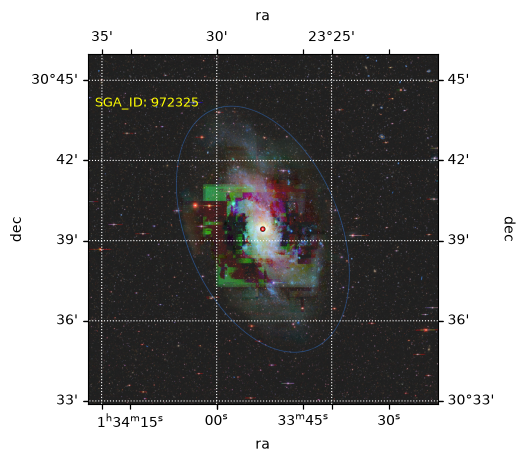

In [10]:
from get_cutouts import get_cutout

from astropy.table import Table
from astropy.visualization.wcsaxes import SphericalCircle
from astropy import units as u

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

from astropy.coordinates import SkyCoord, match_coordinates_sky
import matplotlib.patches as patches

import os

from tqdm import tqdm

# target_galaxies = Table.read('/pscratch/sd/d/dbustos/rot_curves/loa_targs.fits')

# SGA = Table.read('/global/cfs/projectdirs/cosmo/data/sga/2020/SGA-2020.fits', 'ELLIPSE')

# SGA_dict = {}
# for i in range(len(SGA)):
#     SGA_dict[SGA['SGA_ID'][i]] = i

target_galaxies = loa_table[loa_table['SGA_ID']==972325]

fig1 = plt.figure(figsize=(7,5))
colors = plt.get_cmap('Set2')
fiber_radius = (107./70) * u.arcsec

# for each rotation curve galaxy, grab cut out, draw fibers on image, and save image
for sga_id in tqdm(np.unique(target_galaxies['SGA_ID'])):
    
    targ_list = target_galaxies[target_galaxies['SGA_ID']==sga_id]
    
    ra, dec = float(SGA['RA'][SGA_dict[sga_id]]), float(SGA['DEC'][SGA_dict[sga_id]])
    
    # D26 in arcmin
    d26 = SGA['D26'][SGA_dict[sga_id]]

    pix = int(2 * d26*60/0.262)

    dr = 11

    npix = 3000
    # if (pix < 2500):
    #     npix = np.minimum(pix,1024)

    # elif (pix > 2500):
    #     npix = np.minimum(pix,3000)

    try:
        img_file, wcs = get_cutout(sga_id, ra, dec, dr=dr, dir='/pscratch/sd/d/dbustos/Fall26',size=npix, zoom = 11)
        img = mpl.image.imread(img_file)

    except Exception:
        print(sga_id, ':img download error 1')
        os.remove(img_file)

        try:
            img_file, wcs = get_cutout(sga_id, ra, dec, dr=dr, dir='/pscratch/sd/d/dbustos/Fall26',size=npix, zoom = 11)
            img = mpl.image.imread(img_file)

        except Exception:
            print(sga_id, ':img download error 1')
            os.remove(img_file)
            continue
    # try:
    #     img_file, wcs = get_cutout(sga_id, ra, dec, dr=dr, dir='/pscratch/sd/d/dbustos/loa_cutouts/cutouts/',size=npix)
    #     img = mpl.image.imread(img_file)

    # except Exception:
    #     print(sga_id, ':img download error 1')

    #     try:
    #         dr = 11
    #         img_file, wcs = get_cutout(sga_id, ra, dec, dr=dr, dir='/pscratch/sd/d/dbustos/loa_cutouts/cutouts/',size=npix)
    #         img = mpl.image.imread(img_file)
            
    #     except Exception :
    #         print(sga_id, ':img download error 2')
    #         continue
        
        #continue

    ax = fig1.add_subplot(111, projection=wcs)
    ax.imshow(np.flip(img, axis=0))
    ax.set(xlabel='ra', ylabel='dec')
    ax.text(int(0.02*npix), int(0.85*npix), 'SGA_ID: {}'.format(sga_id), fontsize=9, color='yellow')
    overlay = ax.get_coords_overlay('icrs')
    overlay.grid(color='white', ls='dotted');

    # Add the location of the DESI fibers.
    # SDSS fibers are 2" diameter, DESI is 107 um with 70 um/" plate scale.
    r1 = SphericalCircle((ra * u.deg, dec * u.deg), fiber_radius,
                         edgecolor='black', facecolor='none', alpha=0.8, lw=3,
                         transform=ax.get_transform('icrs'))
    r2 = SphericalCircle((ra * u.deg, dec * u.deg), fiber_radius,
                         edgecolor='red', facecolor='none', alpha=0.8, lw=2,
                         transform=ax.get_transform('icrs'))
    ax.add_patch(r1)
    ax.add_patch(r2)

    # num_targs = len(targ_list)
    # legend_handles = [None] * num_targs
    # location = {}

    # for i, targ in enumerate(targ_list):
    #     ra, dec = targ['TARGET_RA'], targ['TARGET_DEC']

    #     if (ra,dec) not in location:
    #         location[(ra,dec)] = colors(len(location))
        
    #     #edgecolor2 = colors(i)
    #     edgecolor2 = location[(ra,dec)]

    #     # Add the location of the DESI fibers.
    #     # SDSS fibers are 2" diameter, DESI is 107 um with 70 um/" plate scale.
    #     r1 = SphericalCircle((ra * u.deg, dec * u.deg), fiber_radius,
    #                          edgecolor='black', facecolor='none', alpha=1, lw=3,
    #                          transform=ax.get_transform('icrs'))
    #     r2 = SphericalCircle((ra * u.deg, dec * u.deg), fiber_radius,
    #                          edgecolor=edgecolor2, facecolor='none', alpha=1, lw=2,
    #                          transform=ax.get_transform('icrs'))
    #     ax.add_patch(r1)
    #     ax.add_patch(r2)

    #     # ax.text(ra, dec, i), transform=ax.get_transform('icrs'), color='white', fontsize=6)
        
    #     legend_handles[i] = patches.Circle((0,0), facecolor = edgecolor2, ec = edgecolor2, lw = 2, label =  str(targ['TARGETID']))
    
    # ax.legend(handles = legend_handles, title = 'SGA ID: {}'.format(sga_id), loc = 'upper right', bbox_to_anchor = (2, 1))
    fig1.subplots_adjust(top=0.85, right=0.85, bottom=0.15, left=0.15)
    
    fig1.savefig('/pscratch/sd/d/dbustos/Fall_26/' + 'cutouts_sga_{}.png'.format(sga_id), bbox_inches = 'tight', dpi=120)
    
    # fig1.clear()